# Freddy: LATTE through the full regional ADCP survey

Choose `SOLO_TRANSECT` below (`F1` by default). Its shallowest accepted **inner** SOLO centre supplies LATTE's initial geographic origin; a rejected SOLO Gaussian radius does not disqualify that centre. LATTE then fits **all ADCP observations in the selected Freddy region at each measured depth**, without restricting them to a SOLO crossing time window. Each accepted LATTE inner centre seeds the next depth; rejected levels leave the previous accepted seed in place.

The overview maps the regional ADCP vectors at the selected SOLO seed depth, the relevant SOLO crossing tracks and their fitted shallowest centres. The remaining diagnostics and 2-D/3-D plots follow the Murphy LATTE and SOLO conventions. Freddy was sampled across several days and two visits, so spatial structure and temporal evolution can be aliased; the fitted depth profile is descriptive, not an instantaneous eddy section. “Surface” means the shallowest observed bin in the selected SOLO crossing. See [info.md](info.md) for data and crossing definitions.

In [1]:
from pathlib import Path
import importlib.util
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.patches import Rectangle

candidates = [Path.cwd(), *Path.cwd().parents,
              Path.cwd() / "seacofs_eddy_tilt_analysis" / "observations"]
OBSERVATIONS_DIR = next(p for p in candidates
                        if p.name == "observations" and (p / "esp_depth_tools.py").is_file())
spec = importlib.util.spec_from_file_location("esp_depth_tools", OBSERVATIONS_DIR / "esp_depth_tools.py")
esp = importlib.util.module_from_spec(spec)
spec.loader.exec_module(esp)

## Controls and SOLO starting centre

Set `VISIT` to `"visit1"`, `"visit2"`, or `"both"` for the buffered crossing set. With `"both"`, buffered LATTE fits F1–F9; the regional LATTE section still uses only the footprint of `SOLO_TRANSECT`, so run it once per seed visit if you want both regional fits. Change `SOLO_TRANSECT` to a crossing in that visit. F1–F7 use the early Freddy regional footprint; F8–F9 use the later visit's footprint. Each footprint uses all ADCP measurements inside it, with no transect-time restriction. The `visit1` label names a geographic footprint and includes some later observations that passed through it. The overview uses the chosen SOLO seed depth so its crossing is visible even when another instrument measured a shallower bin elsewhere.

The 50 km LATTE core admits two-dimensional samples around the centre; the 150 km outer limit bounds the Gaussian fit. These differ from SOLO's along-track 25 km core and match the Murphy LATTE controls.

In [2]:
EDDY = "Freddy"
VISIT = "visit1"  # "visit1": F1-F7; "visit2": F8-F9; "both": F1-F9 buffered.
if VISIT not in ("visit1", "visit2", "both"):
    raise ValueError("VISIT must be 'visit1', 'visit2', or 'both'")
SOLO_TRANSECT = "F8" if VISIT == "visit2" else "F2"  # Editable SOLO seed within the visit.
STUDY_DIR = OBSERVATIONS_DIR / "MNF_IN2015_V03_adcp_trawler"
INFO_PATH = STUDY_DIR / "info.md"
BACKEND_PATH = Path("/home/z5297792/ESP_zonodo/functions.py")
DATA_PATH, transects, adcp = esp.load_study(INFO_PATH, EDDY)
visit_ids = [f"F{i}" for i in (range(1, 8) if VISIT == "visit1" else range(8, 10) if VISIT == "visit2" else range(1, 10))]
transects = transects.loc[visit_ids]
OUTPUT_DIR = DATA_PATH.parent / "outputs"
SOLO_RESULTS_PATH = OUTPUT_DIR / "freddy_solo_depth_fits.csv"
FREDDY_BOUNDS_BY_VISIT = {
    "visit1": (152.8, 153.5, -32.9, -32.3),
    "visit2": (153.5, 154.2, -33.6, -33.0),
}  # west, east, south, north; geographic regions, not transect windows
REGIONAL_VISIT = "visit1" if SOLO_TRANSECT in {f"F{i}" for i in range(1, 8)} else "visit2"
FREDDY_BOUNDS = FREDDY_BOUNDS_BY_VISIT[REGIONAL_VISIT]
MIN_ATTENDANCE = None

FIT = dict(core_radius=20_000., outer_radius=50_000.,
           max_centre_step=200_000., radius_limit=150_000.,
           min_core_points=1, min_outer_points=1,
           expected_sign=-1, require_peak_bracket=True)
MAP_DEPTHS = (30, 100, 200, 300, 400, 500, 600, 700) if REGIONAL_VISIT == "visit1" else (18, 100, 200, 290)
HALF_WIDTH_KM = 40
VELOCITY_LIMIT = 1

if SOLO_TRANSECT not in transects.index:
    raise ValueError(f"SOLO_TRANSECT must be one of {list(transects.index)}")
solo = pd.read_csv(SOLO_RESULTS_PATH)
required = {"transect_id", "depth_m", "inner_valid", "xc_lon", "yc_lat"}
if not required.issubset(solo.columns):
    raise ValueError(f"Missing SOLO output columns: {required - set(solo.columns)}")
solo["inner_valid"] = solo.inner_valid.astype(str).str.lower().eq("true")
selected = solo.loc[solo.transect_id.eq(SOLO_TRANSECT) & solo.inner_valid].sort_values("depth_m")
if selected.empty:
    raise ValueError(f"No accepted SOLO inner centre for {SOLO_TRANSECT}")
SOLO_REF = selected.iloc[0]
ORIGIN_LON_LAT = (float(SOLO_REF.xc_lon), float(SOLO_REF.yc_lat))
west, east, south, north = FREDDY_BOUNDS
if not (west <= ORIGIN_LON_LAT[0] <= east and south <= ORIGIN_LON_LAT[1] <= north):
    raise ValueError("Selected SOLO centre lies outside the chosen Freddy region")
print(f"LATTE initial centre: {SOLO_TRANSECT} SOLO inner fit at {SOLO_REF.depth_m:g} m, "
      f"({ORIGIN_LON_LAT[0]:.5f}°E, {abs(ORIGIN_LON_LAT[1]):.5f}°S); "
      f"Gaussian status: {SOLO_REF.status}; regional footprint: {REGIONAL_VISIT}; crossings: {VISIT}")

LATTE initial centre: F2 SOLO inner fit at 30.4 m, (153.15480°E, 32.61206°S); Gaussian status: outer_radius_limit; regional footprint: visit1; crossings: visit1


## Surface ADCP overview

Grey arrows sample all Freddy-region observations at the chosen SOLO seed depth. Coloured lines show crossings from the selected visit; crosses mark their shallowest accepted inner centres. The red frame is the regional selection. These vectors and tracks were sampled at different times.

selected_rows                                              34400
used_rows                                                  34400
unique_times                                                 851
start_utc                              2015-06-08 21:51:20+00:00
end_utc                                2015-06-16 10:42:37+00:00
depth_range_m                                      [18.5, 814.4]
missing_avg_qc                                             34400
zero_attendance_rows                                       14073
min_attendance                                              None
origin_lon_lat          (153.15480028983367, -32.61206114619023)
bounds_lon_lat                      (152.8, 153.5, -32.9, -32.3)
Name: LATTE selection audit, dtype: object

path                 /home/z5297792/ESP_zonodo/functions.py
sha256    8e4b06fe4c144f7a70671ee913b6d27784f9cdb587e9b0...
Name: ESP backend, dtype: object

,rows,times,shallowest_m,deepest_m,first_utc,last_utc
Datafile,,,,,,
in2015_v03_os150nb.nc,5729,227,18.5,290.5,2015-06-12 07:17:32+00:00,2015-06-16 10:42:37+00:00
in2015_v03_os75nb.nc,28671,624,30.4,814.4,2015-06-08 21:51:20+00:00,2015-06-11 21:21:43+00:00


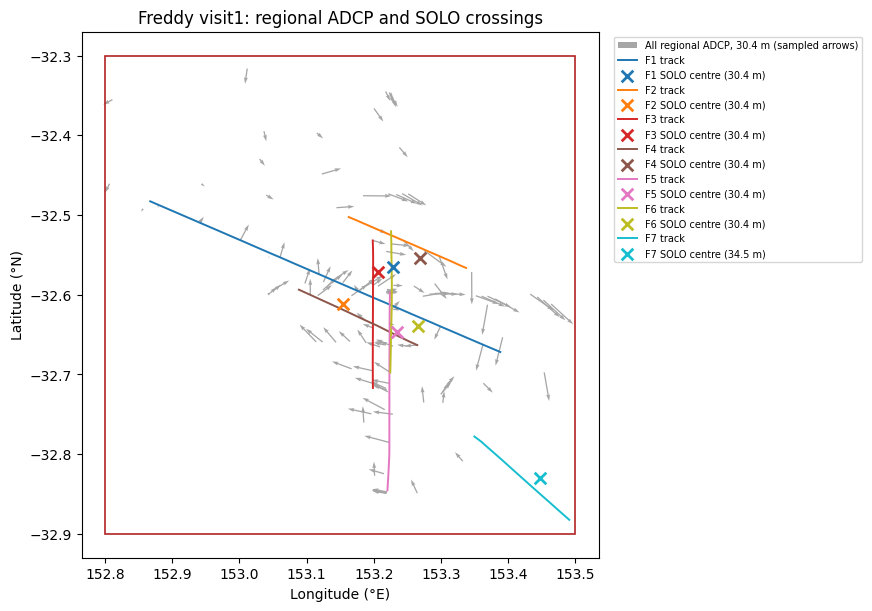

In [3]:
backend, backend_info = esp.load_backend(BACKEND_PATH)
data, coverage, audit = esp.load_observations(
    DATA_PATH, None, None, ORIGIN_LON_LAT,
    min_attendance=MIN_ATTENDANCE, bounds=FREDDY_BOUNDS)
display(pd.Series(audit, name="LATTE selection audit"))
display(pd.Series(backend_info, name="ESP backend"))
display(data.groupby("Datafile").agg(
    rows=("depth", "size"), times=("time", "nunique"),
    shallowest_m=("depth", "min"), deepest_m=("depth", "max"),
    first_utc=("time", "min"), last_utc=("time", "max")))

shown_depth = float(coverage.index[np.argmin(abs(coverage.index.to_numpy(float) - SOLO_REF.depth_m))])
surface = data.loc[data.depth.eq(shown_depth)].sort_values("time")
fig, ax = plt.subplots(figsize=(9, 6), constrained_layout=True)
shown = surface.iloc[::max(1, len(surface)//120)]
ax.quiver(shown.lon, shown.lat, shown.u, shown.v, color="0.65", width=.0025,
          scale=17, label=f"All regional ADCP, {shown_depth:g} m (sampled arrows)")
visit_ids = [f"F{i}" for i in (range(1, 8) if REGIONAL_VISIT == "visit1" else range(8, 10))]
for colour, ident in zip(plt.cm.tab10(np.linspace(0, 1, len(visit_ids))), visit_ids):
    crossing = transects.loc[ident]
    track = data.loc[data.time.between(pd.Timestamp(crossing.start), pd.Timestamp(crossing.end))]
    track = track.sort_values("time").drop_duplicates("time")
    ax.plot(track.lon, track.lat, color=colour, lw=1.4, label=f"{ident} track")
    fitted = solo.loc[solo.transect_id.eq(ident) & solo.inner_valid].sort_values("depth_m")
    if not fitted.empty:
        first = fitted.iloc[0]
        ax.scatter(first.xc_lon, first.yc_lat, marker="x", s=70, lw=2,
                   color=colour, zorder=5, label=f"{ident} SOLO centre ({first.depth_m:g} m)")
ax.add_patch(Rectangle((FREDDY_BOUNDS[0], FREDDY_BOUNDS[2]),
                       FREDDY_BOUNDS[1]-FREDDY_BOUNDS[0],
                       FREDDY_BOUNDS[3]-FREDDY_BOUNDS[2],
                       fill=False, edgecolor="firebrick", lw=1.2))
ax.set(xlabel="Longitude (°E)", ylabel="Latitude (°N)",
       title=f"Freddy {REGIONAL_VISIT}: regional ADCP and SOLO crossings")
ax.set_aspect(1/np.cos(np.deg2rad(surface.lat.mean())))
ax.legend(fontsize=7, bbox_to_anchor=(1.02, 1), loc="upper left")
plt.show()

## LATTE fits from shallow to deep

Every depth uses the full regional sample at that depth. Accepted inner fits update the centre and ellipse used to select the next core, even if the Gaussian outer stage fails. The table retains failed levels and separates centre support from reconstruction support.

LATTE: 32/85 accepted inner fits; 32/85 accepted Gaussian reconstructions.
status
collinear_latte_sampling     3
insufficient_core            2
invalid_ellipse             48
ok                          32
Centre offsets reference the shallowest accepted fit: 30.4 m.
Reconstructed measured levels: 30.4–526.4 m (gaps retained).
The ADCP sampling limit is not an estimate of the eddy bottom. R² is in-sample.


,depth_m,status,n_obs,n_core,inner_valid,valid,core_spread_ratio,inner_R2,alpha,Rc_m,vector_R2
0,18.5,invalid_ellipse,39,18,False,False,0.0002,0.7874,NaN,NaN,NaN
1,26.5,invalid_ellipse,39,18,False,False,0.0002,0.8806,NaN,NaN,NaN
2,30.4,ok,624,444,True,True,0.7520,0.5797,1.7693,22202.3041,0.6056
3,34.5,invalid_ellipse,227,159,False,False,0.3295,0.4676,NaN,NaN,NaN
4,42.5,invalid_ellipse,227,159,False,False,0.3295,0.4793,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...
80,750.4,invalid_ellipse,540,81,False,False,0.8674,0.1043,NaN,NaN,NaN
81,766.4,invalid_ellipse,529,77,False,False,0.8076,0.1089,NaN,NaN,NaN
82,782.4,insufficient_core,446,0,False,False,0.5971,0.0951,NaN,NaN,NaN
83,798.4,invalid_ellipse,226,37,False,False,0.3454,0.3112,NaN,NaN,NaN


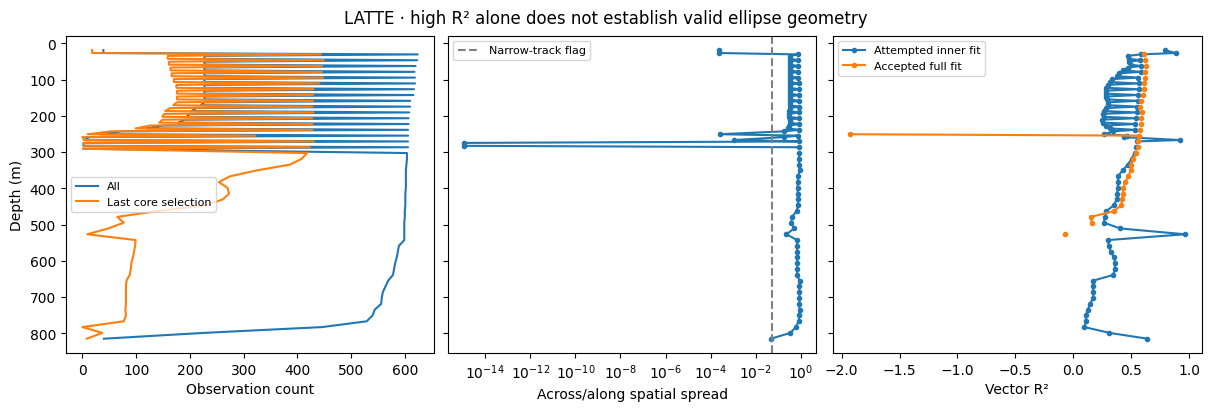

In [4]:
results, samples = esp.fit_depths(
    data, backend, "LATTE", depth_levels=coverage.index, **FIT)
esp.report(results)
columns = ["depth_m", "status", "n_obs", "n_core", "inner_valid", "valid",
           "core_spread_ratio", "inner_R2", "alpha", "Rc_m", "vector_R2"]
with pd.option_context("display.max_rows", 60):
    display(results[columns].round(4))
esp.plot_diagnostics(results)
plt.show()

## Centre trajectory and reconstruction

Offsets are relative to LATTE's shallowest accepted centre; the chosen SOLO centre is only its initial seed. The horizontal maps, 3-D view and fixed zonal/meridional sections use the same helper and scales as the Murphy LATTE notebook. Reconstructed flow away from sampled points is model-based extrapolation. Levels from OS75 and OS150 are kept at their original measured depths, so their spatial and temporal support can differ; the deepest ADCP bin does not define the eddy bottom.

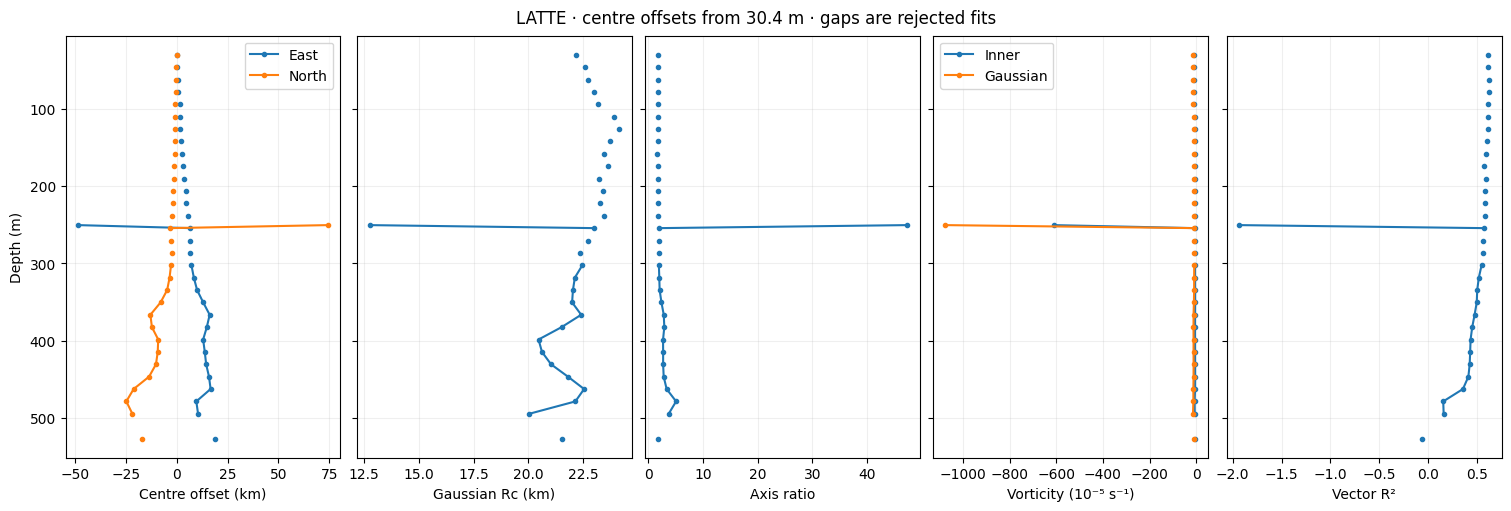

In [5]:
esp.plot_profiles(results)
plt.show()

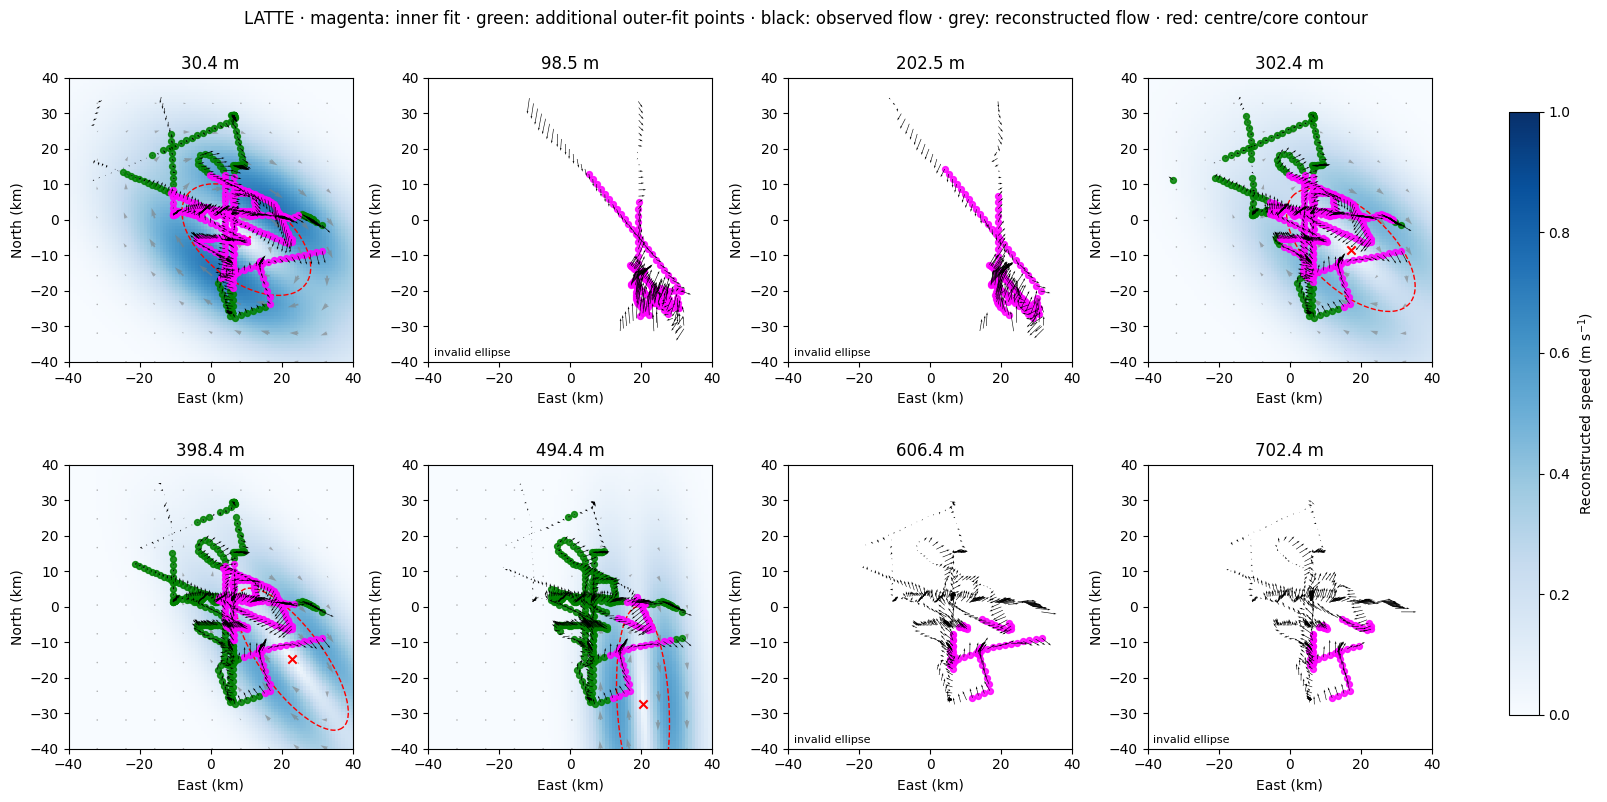

In [6]:
esp.plot_maps(results, samples, backend, depths=MAP_DEPTHS,
              half_width_km=HALF_WIDTH_KM, speed_max=VELOCITY_LIMIT)
plt.show()

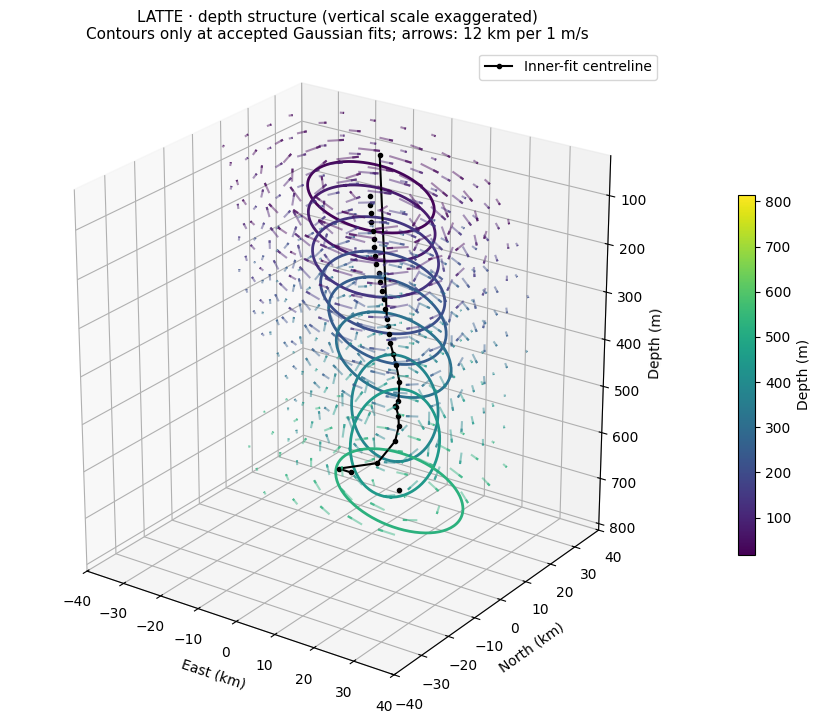

In [7]:
esp.plot_3d(results, backend, half_width_km=HALF_WIDTH_KM)
plt.show()

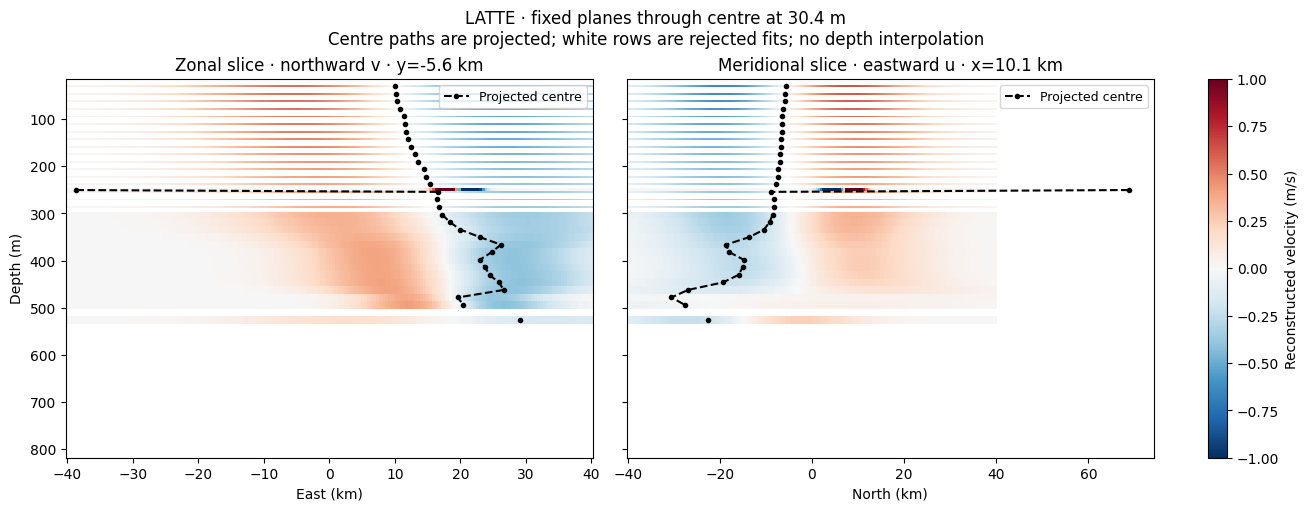

In [8]:
esp.plot_sections(results, backend, half_width_km=HALF_WIDTH_KM,
                  speed_max=VELOCITY_LIMIT)
plt.show()

## Export to scratch

The CSV includes accepted and rejected depths. The companion JSON records the full regional selection, SOLO seed, visit, fit settings and backend fingerprint. Both stay beside this voyage's input CSV under `outputs/`.

In [9]:
SAVE_RESULTS = True
if SAVE_RESULTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    results.to_csv(OUTPUT_DIR / "freddy_latte_depth_fits.csv", index=False)
    provenance = dict(eddy=EDDY, method="LATTE", visit=REGIONAL_VISIT, selected_visits=VISIT,
                      bounds_lon_lat=FREDDY_BOUNDS,
                      data_path=str(DATA_PATH), info_path=str(INFO_PATH),
                      backend=backend_info,
                      solo_results_path=str(SOLO_RESULTS_PATH),
                      solo_transect=SOLO_TRANSECT,
                      solo_surface_fit=SOLO_REF.to_dict(),
                      selection=audit, fit_settings=FIT)
    (OUTPUT_DIR / "freddy_latte_provenance.json").write_text(
        json.dumps(provenance, indent=2, default=str))
    print(f"Saved LATTE results to {OUTPUT_DIR}")

Saved LATTE results to /srv/scratch/z5297792/tilt_observation_data/MNF_IN2015_V03_adcp_trawler/outputs


## LATTE around the SOLO crossings, with time buffers

This is a **separate** application from the full regional LATTE fit above. The crossing times come from `info.md`; the editable buffers expand each end. Every crossing is fitted independently, starting from its own shallowest accepted SOLO inner centre. LATTE uses all ADCP samples in the expanded time window, including the off-line ship track; no straight-transect or geographic footprint filter is applied. If you edit `info.md` or SOLO settings, rerun the corresponding SOLO notebook and its export first so these starting centres match the crossings.


,before_h,after_h,start_utc,end_utc,times,bins,inner_fits,gaussian_fits,surface_status,solo_seed_depth_m
transect,,,,,,,,,,
F1,5.0,5.0,2015-06-08 17:15:00+00:00,2015-06-09 06:55:00+00:00,163,50,38,38,ok,30.4
F2,5.0,5.0,2015-06-08 22:00:00+00:00,2015-06-09 09:30:00+00:00,137,50,38,38,ok,30.4
F3,5.0,5.0,2015-06-09 00:50:00+00:00,2015-06-09 12:20:00+00:00,138,50,39,39,ok,30.4
F4,6.0,6.0,2015-06-09 07:45:00+00:00,2015-06-09 20:45:00+00:00,156,49,24,24,ok,30.4
F5,6.0,6.0,2015-06-09 15:00:00+00:00,2015-06-10 04:30:00+00:00,162,50,21,21,ok,30.4
F6,10.0,10.0,2015-06-09 16:15:00+00:00,2015-06-10 13:15:00+00:00,252,50,21,21,ok,30.4
F7,6.0,6.0,2015-06-12 09:30:00+00:00,2015-06-12 23:00:00+00:00,162,30,27,27,ok,34.5


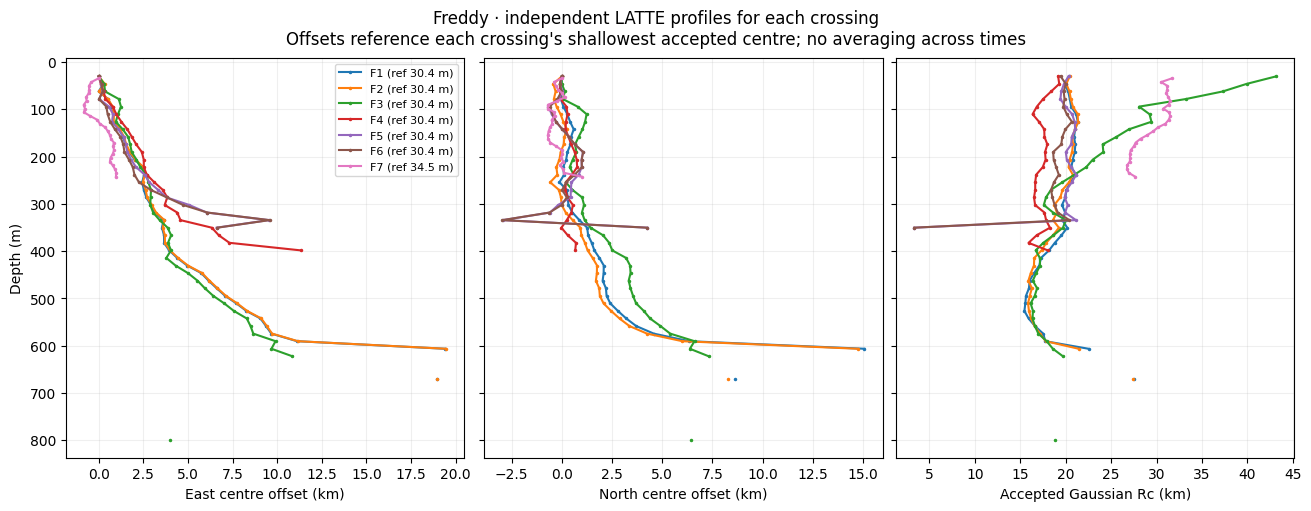

In [10]:
BUFFER_BEFORE_HOURS = 5.0  # Added before each SOLO crossing (UTC hours).
BUFFER_AFTER_HOURS = 5.0   # Added after each SOLO crossing (UTC hours).
BUFFER_OVERRIDES = {'F1': (5.0, 5.0), 'F2': (5.0, 5.0), 'F3': (5.0, 5.0), 'F4': (6.0, 6.0),
                    'F5': (6.0, 6.0), 'F6': (10.0, 10.0), 'F7': (6.0, 6.0), 'F8': (0.0, 6.0), 'F9': (6.0, 12.0)}     # Optional, e.g. {"M1": (2.0, 1.5)} or {"F7": (1.0, 2.0)}.
# BUFFER_FIT = FIT.copy()   # Same LATTE settings as the regional run; edit independently if needed.
BUFFER_FIT = dict(core_radius=10_000., outer_radius=40_000.,
           max_centre_step=200_000., radius_limit=150_000.,
           min_core_points=1, min_outer_points=1,
           expected_sign=-1, require_peak_bracket=False)

ACTIVE_BUFFER_OVERRIDES = {k: v for k, v in BUFFER_OVERRIDES.items() if k in transects.index}
buffered_runs, buffered_summary, buffered_results = esp.fit_buffered_latte_transects(
    DATA_PATH, transects, solo, backend, BUFFER_FIT,
    before_hours=BUFFER_BEFORE_HOURS, after_hours=BUFFER_AFTER_HOURS,
    buffer_overrides=ACTIVE_BUFFER_OVERRIDES, min_attendance=MIN_ATTENDANCE)
display(buffered_summary)
esp.plot_transect_comparison(buffered_runs, EDDY)
plt.show()


## Selected buffered crossing: diagnostics and depth structure

Change `ACTIVE_BUFFERED_TRANSECT` in the next cell and rerun the detailed plots to inspect another crossing. Magenta and green dots in the horizontal maps identify the inner and additional outer-fit ADCP samples. Failed fits remain visible in the diagnostics and are not reconstructed.


selected_rows                                               4973
used_rows                                                   4973
unique_times                                                 163
start_utc                              2015-06-08 17:16:22+00:00
end_utc                                2015-06-09 06:51:21+00:00
depth_range_m                                      [30.4, 814.4]
missing_avg_qc                                              4973
zero_attendance_rows                                        2367
min_attendance                                              None
origin_lon_lat          (153.22941360829947, -32.56530319164083)
bounds_lon_lat                                              None
window_start_utc                       2015-06-08 17:15:00+00:00
window_end_utc                         2015-06-09 06:55:00+00:00
buffer_before_hours                                          5.0
buffer_after_hours                                           5.0
solo_seed_depth_m        

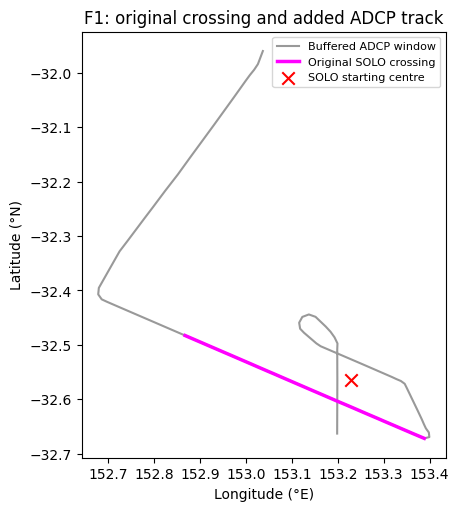

LATTE: 38/50 accepted inner fits; 38/50 accepted Gaussian reconstructions.
status
invalid_ellipse    12
ok                 38
Centre offsets reference the shallowest accepted fit: 30.4 m.
Reconstructed measured levels: 30.4–670.4 m (gaps retained).
The ADCP sampling limit is not an estimate of the eddy bottom. R² is in-sample.


,depth_m,status,n_obs,n_core,inner_valid,valid,xc_lon,yc_lat,Rc_m,vector_R2
0,30.4,ok,163,47,True,True,153.2026,-32.5844,20333.1169,0.8054
1,46.4,ok,163,47,True,True,153.2054,-32.5847,19872.2622,0.8261
2,62.4,ok,144,48,True,True,153.2026,-32.5847,20277.6027,0.8237
3,78.4,ok,121,46,True,True,153.2082,-32.5847,20449.1155,0.8564
4,94.4,ok,105,48,True,True,153.2104,-32.5837,20601.7170,0.8631
5,110.4,ok,104,47,True,True,153.2112,-32.5819,21152.5216,0.8562
6,126.4,ok,103,48,True,True,153.2111,-32.5806,21329.8861,0.8623
7,142.4,ok,103,47,True,True,153.2149,-32.5790,21034.3912,0.8762
8,158.4,ok,102,47,True,True,153.2173,-32.5802,20923.7648,0.8853
9,174.4,ok,102,48,True,True,153.2186,-32.5805,21056.6768,0.9016


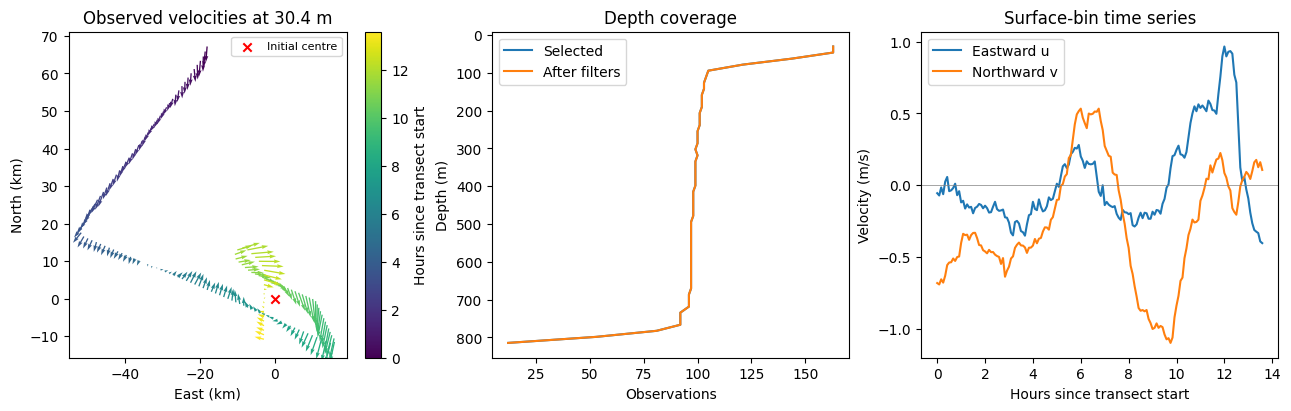

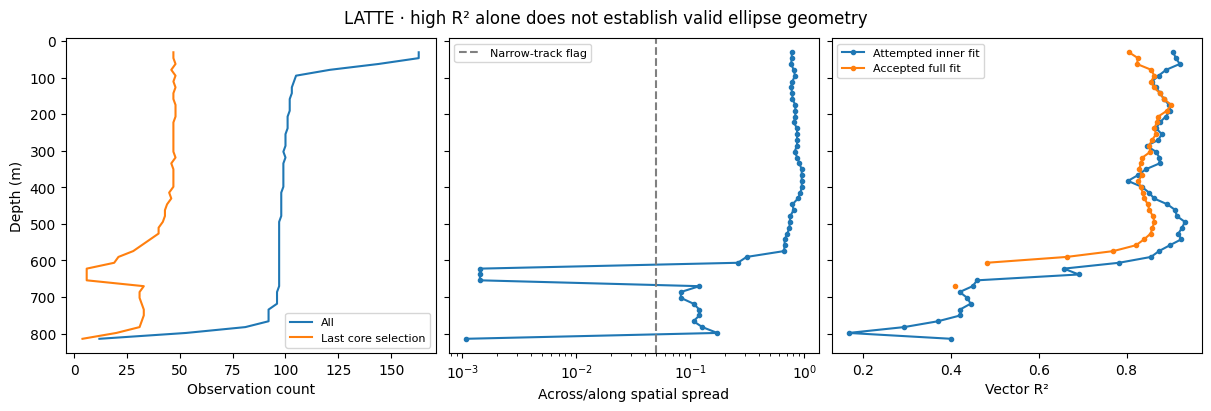

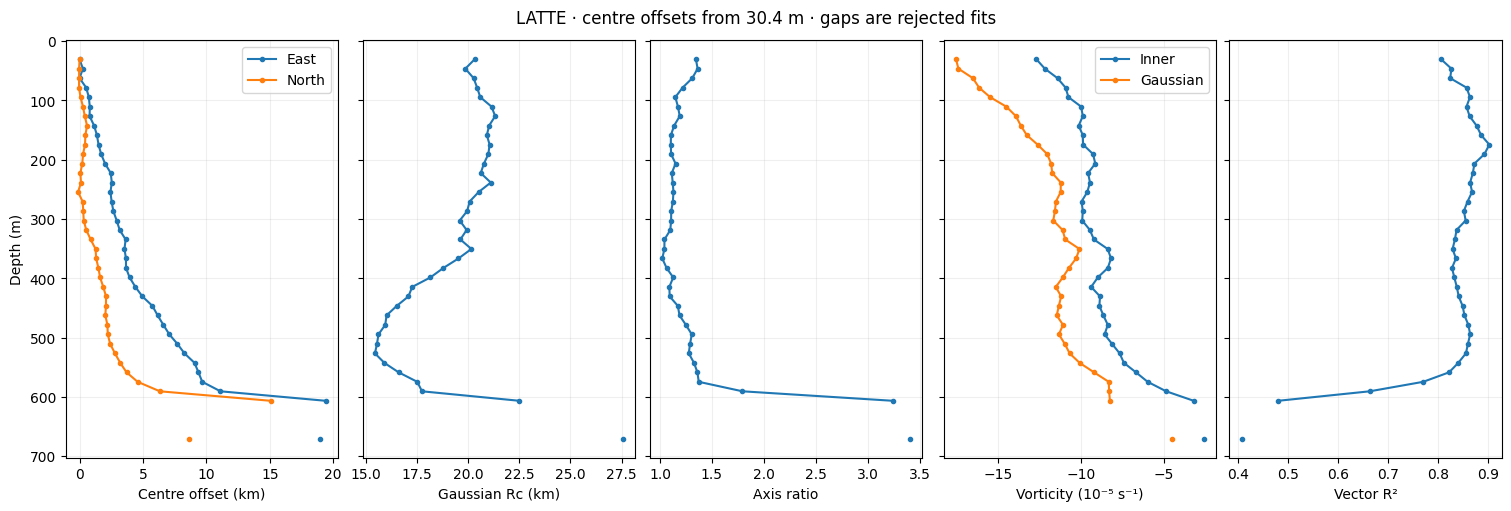

In [16]:
ACTIVE_BUFFERED_TRANSECT = "F1" 
if ACTIVE_BUFFERED_TRANSECT not in buffered_runs:
    raise ValueError(f"Choose one of {list(buffered_runs)}")
buffered_run = buffered_runs[ACTIVE_BUFFERED_TRANSECT]
buffered_data = buffered_run["data"]
buffered_coverage = buffered_run["coverage"]
buffered_result = buffered_run["results"]
buffered_samples = buffered_run["samples"]
display(pd.Series(buffered_run["audit"], name=ACTIVE_BUFFERED_TRANSECT))
crossing = transects.loc[ACTIVE_BUFFERED_TRANSECT]
track = buffered_data.sort_values("time").drop_duplicates("time")
original = track.time.between(pd.Timestamp(crossing.start), pd.Timestamp(crossing.end))
fig, ax = plt.subplots(figsize=(6, 5), layout="constrained")
ax.plot(track.lon, track.lat, color="0.6", lw=1.5, label="Buffered ADCP window")
ax.plot(track.loc[original, "lon"], track.loc[original, "lat"],
        color="magenta", lw=2.5, label="Original SOLO crossing")
seed = buffered_run["solo_seed"]
ax.scatter(seed.xc_lon, seed.yc_lat, marker="x", s=80, color="red", label="SOLO starting centre")
ax.set(xlabel="Longitude (°E)", ylabel="Latitude (°N)",
       title=f"{ACTIVE_BUFFERED_TRANSECT}: original crossing and added ADCP track")
ax.set_aspect(1/np.cos(np.deg2rad(track.lat.median())))
ax.legend(fontsize=8)
plt.show()
esp.report(buffered_result)
display(buffered_result[["depth_m", "status", "n_obs", "n_core", "inner_valid", "valid",
                         "xc_lon", "yc_lat", "Rc_m", "vector_R2"]].round(4))
esp.plot_sampling(buffered_data, buffered_coverage)
plt.show()
esp.plot_diagnostics(buffered_result)
plt.show()
esp.plot_profiles(buffered_result)
plt.show()


## Selected buffered crossing: reconstructed flow

Horizontal maps show nearest measured depths, including rejected levels. The 3-D and fixed zonal/meridional sections use the same conventions as the regional LATTE figures above.


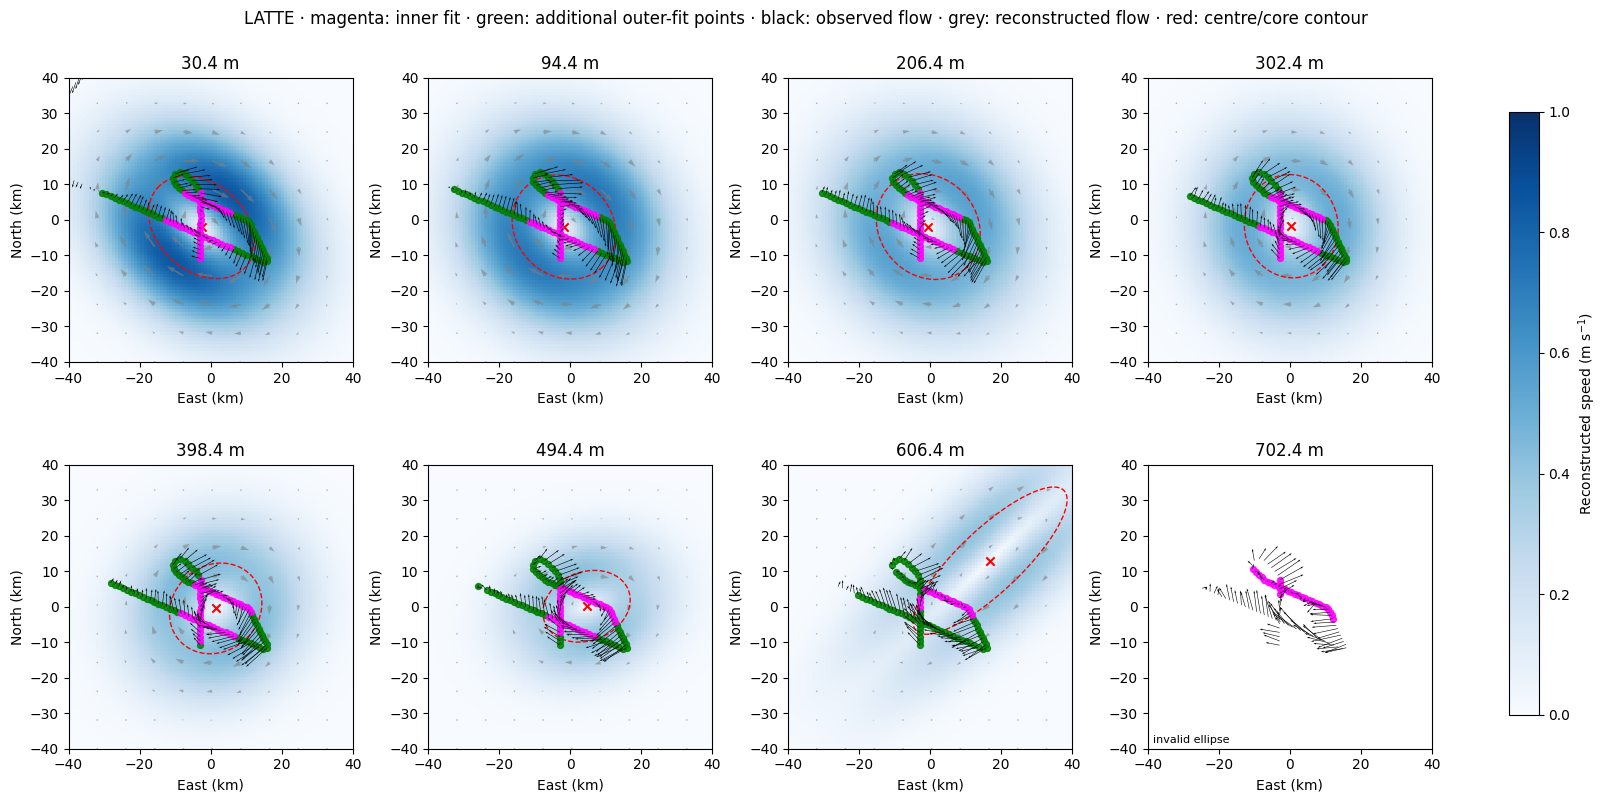

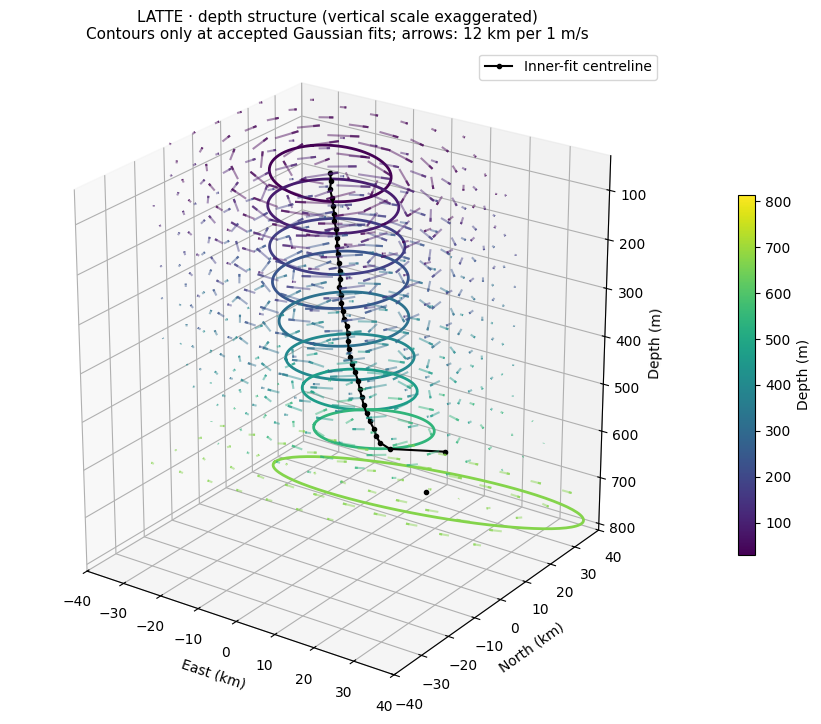

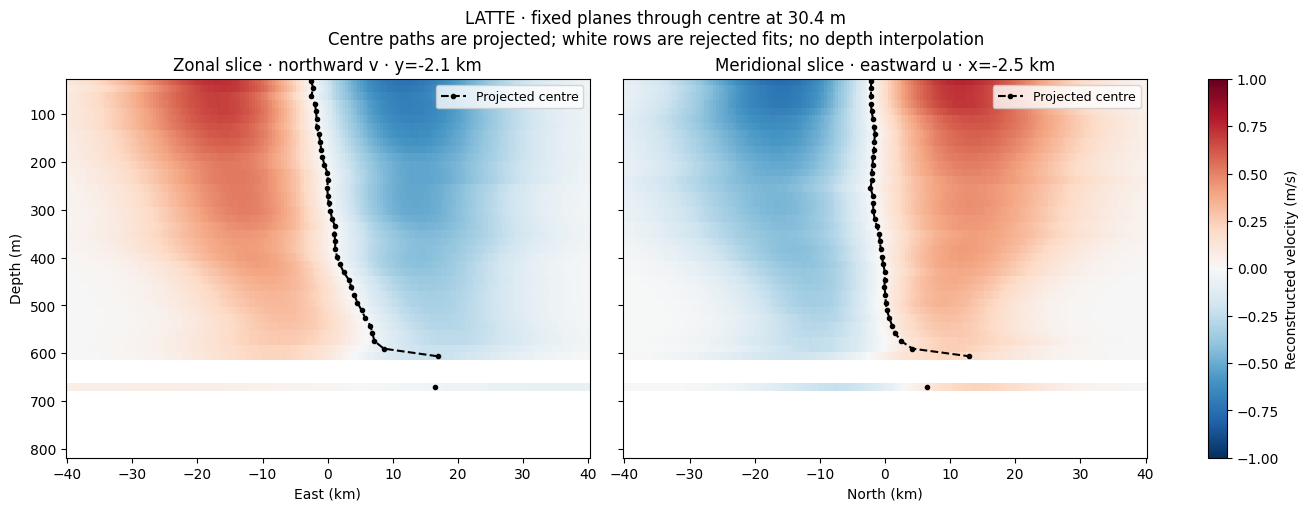

In [17]:
BUFFER_MAP_DEPTHS = (30, 100, 200, 300, 400, 500, 600, 700) if ACTIVE_BUFFERED_TRANSECT in {f"F{i}" for i in range(1, 8)} else (18, 100, 200, 290)
esp.plot_maps(buffered_result, buffered_samples, backend, depths=BUFFER_MAP_DEPTHS,
              half_width_km=HALF_WIDTH_KM, speed_max=VELOCITY_LIMIT)
plt.show()
esp.plot_3d(buffered_result, backend, half_width_km=HALF_WIDTH_KM)
plt.show()
esp.plot_sections(buffered_result, backend, half_width_km=HALF_WIDTH_KM,
                  speed_max=VELOCITY_LIMIT)
plt.show()


## Export buffered-transect LATTE results

These files are separate from the full regional LATTE export. They retain every depth and crossing, actual selected times, per-crossing buffers, SOLO seed depth and fit settings.


In [13]:
SAVE_BUFFERED_RESULTS = True
if SAVE_BUFFERED_RESULTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    buffered_results.to_csv(OUTPUT_DIR / "freddy_latte_buffered_depth_fits.csv", index=False)
    buffered_provenance = dict(eddy=EDDY, method="LATTE", selection="SOLO crossings plus time buffers",
                               data_path=str(DATA_PATH), info_path=str(INFO_PATH),
                               solo_results_path=str(SOLO_RESULTS_PATH), backend=backend_info,
                               before_hours=BUFFER_BEFORE_HOURS, after_hours=BUFFER_AFTER_HOURS,
                               buffer_overrides=ACTIVE_BUFFER_OVERRIDES, fit_settings=BUFFER_FIT,
                               crossings={ident: run["audit"] for ident, run in buffered_runs.items()})
    (OUTPUT_DIR / "freddy_latte_buffered_provenance.json").write_text(
        json.dumps(buffered_provenance, indent=2, default=str))
    print(f"Saved buffered LATTE results to {OUTPUT_DIR}")


Saved buffered LATTE results to /srv/scratch/z5297792/tilt_observation_data/MNF_IN2015_V03_adcp_trawler/outputs
